In [1]:
import sys
sys.path.append("../../../")

In [2]:
import sys
import skimage
import imagecorruptions

print("Python:", sys.executable)
print("scikit-image:", skimage.__version__)
print("imagecorruptions:", imagecorruptions.__file__)

Python: /Users/serenelobo/Library/Mobile Documents/com~apple~CloudDocs/Documents/University/comp9517-computer vision/cs9517/basilisk/.venv/bin/python
scikit-image: 0.26.0
imagecorruptions: /Users/serenelobo/Library/Mobile Documents/com~apple~CloudDocs/Documents/University/comp9517-computer vision/cs9517/basilisk/.venv/lib/python3.11/site-packages/imagecorruptions/__init__.py


/Users/serenelobo/Library/Mobile Documents/com~apple~CloudDocs/Documents/University/comp9517-computer vision/cs9517/basilisk/.venv/lib/python3.11/site-packages/imagecorruptions/corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [3]:
from src.utils.dataset import load_dataset
from src.methods.deep_learning.deep_learning import DeepLearningDetector
from src.evaluation.evaluator import Evaluator
from src.experiments.experiment_runner import (
    CleanExperiment,
    RandomSeverityExperiment,
    SeveritySweepExperiment,
    RandomCompositeExperiment
)
from src.experiments.transforms.corruptions import GaussianBlur

In [4]:

val_dataset = load_dataset("val")

detector = DeepLearningDetector()

detectors = {
    "deep_learning": detector
}

print(f"Loaded {len(val_dataset)} validation images")

Loaded 291 validation images


In [5]:
# evaluator = Evaluator(detector)

# results = evaluator.evaluate(val_dataset, title="Testing Function")

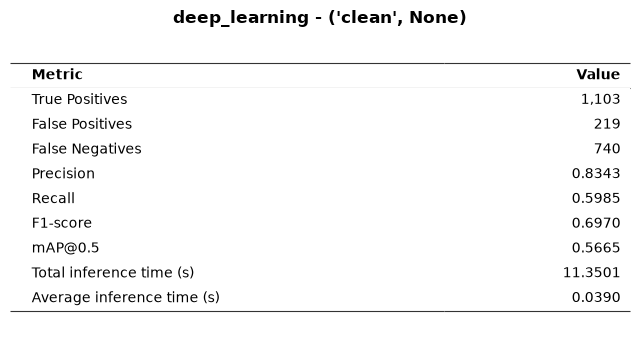

In [6]:
clean_experiment = CleanExperiment()

clean_results = clean_experiment.run(
    dataset=val_dataset,
    detectors=detectors
)

In [7]:
baseline = clean_results[0][("clean", None)]["deep_learning"]

# print(f"mAP@0.5: {baseline['map50']:.4f}")
# print(f"Precision: {baseline['precision']:.4f}")
# print(f"Recall: {baseline['recall']:.4f}")

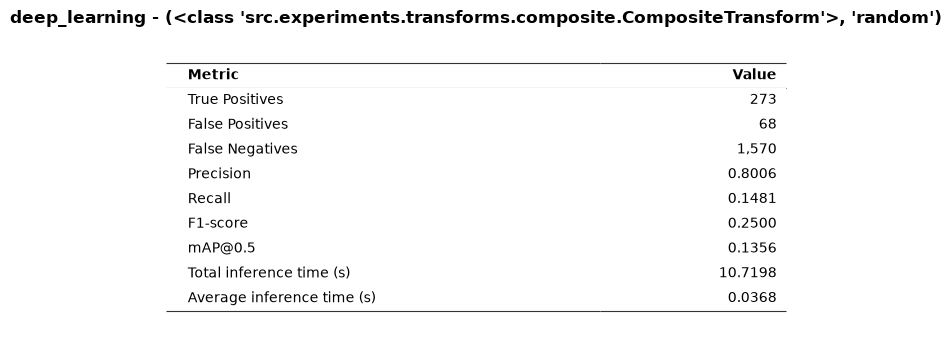

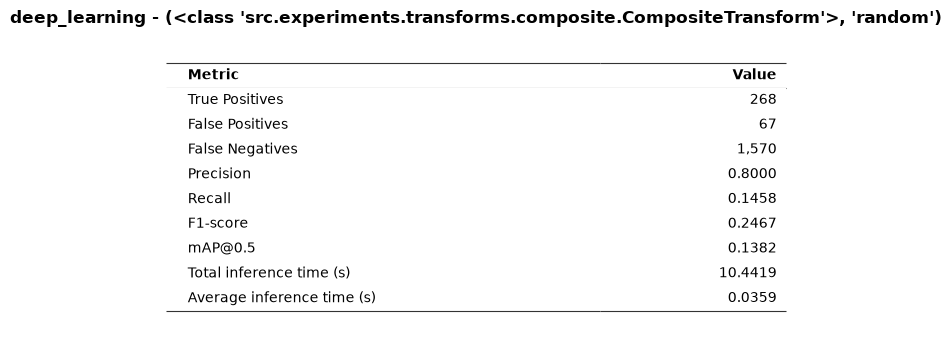

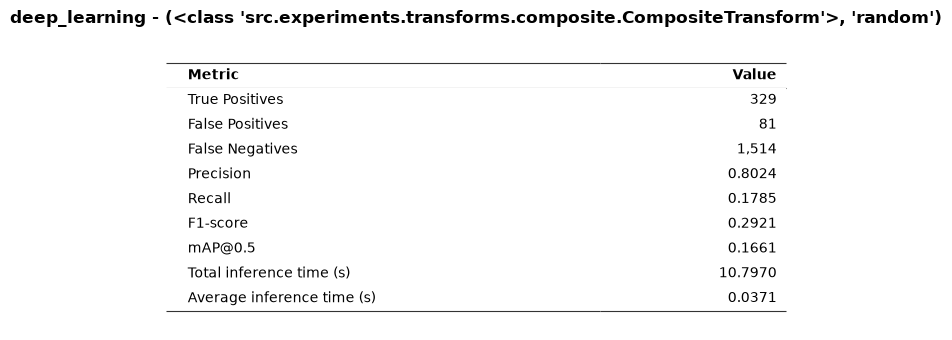

In [9]:
random_results = RandomCompositeExperiment(runs=3).run(val_dataset, detectors)

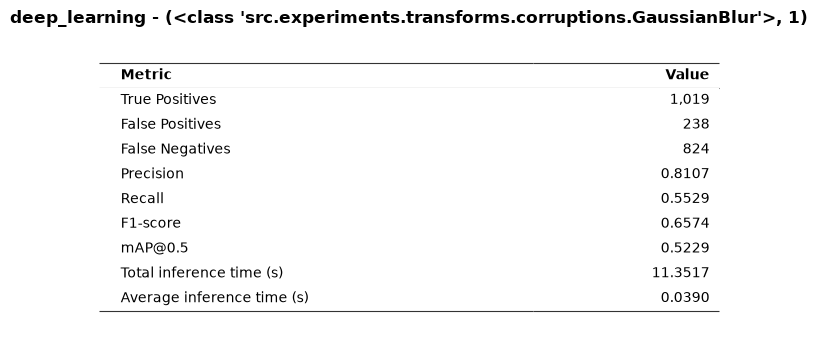

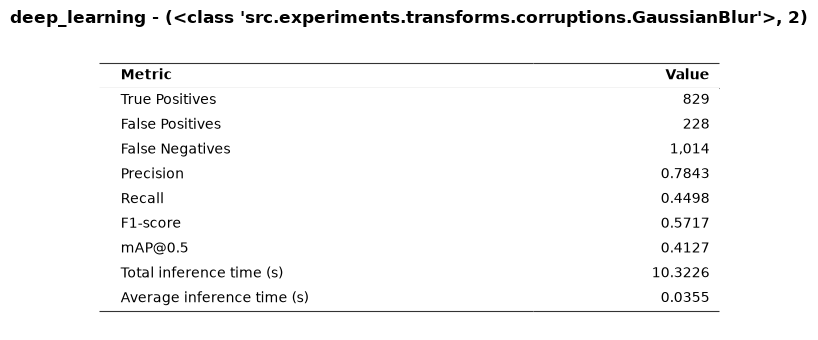

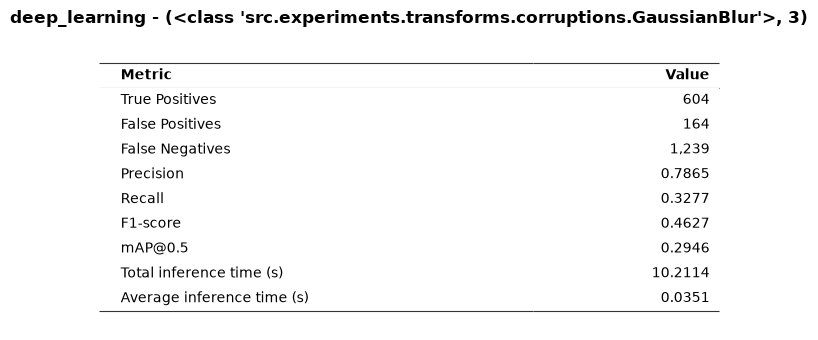

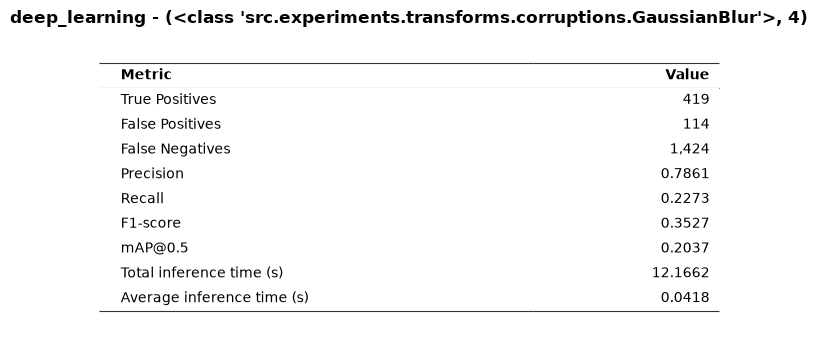

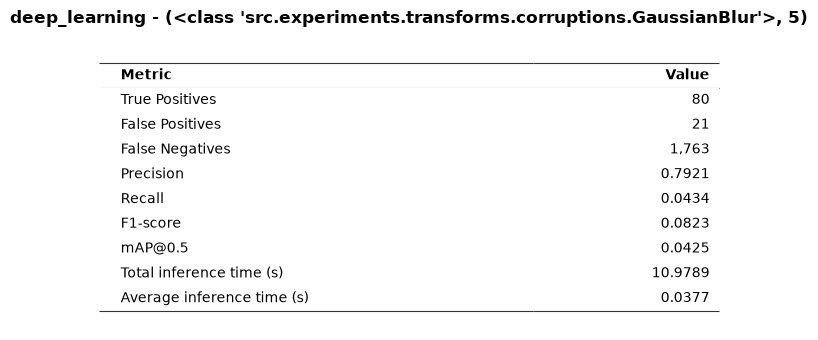

In [10]:
blur_results = SeveritySweepExperiment(
    corruptions=[GaussianBlur()]
).run(val_dataset, detectors)